# Week 2 실습: 교환가능성, 우도원리, HPD 구간

개념 정리는 [notes.md](./notes.md) 참고.

In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
plt.rcParams["figure.figsize"] = (7, 4)

## 1. 교환가능하지만 독립은 아니다

$\theta\sim Unif(0,1)$, $X_i\mid\theta\overset{iid}{\sim}Ber(\theta)$로 데이터를 생성하면 $P(X_1=\dots=X_n=1)=1/(n+1)$이고, 독립이라면 $1/2^n$이어야 한다. 시뮬레이션으로 확인.

In [2]:
N = 200_000
results = []
for n in [1, 2, 3, 5, 8]:
    theta = rng.uniform(0, 1, N)
    X = rng.binomial(1, theta[:, None], size=(N, n))
    p_all_one = X.all(axis=1).mean()
    results.append((n, p_all_one, 1/(n+1), 0.5**n))
print(f"{'n':>2} | {'simulated':>9} | {'1/(n+1)':>8} | {'1/2^n':>8}")
for n, s, ex, ind in results:
    print(f"{n:>2} | {s:9.4f} | {ex:8.4f} | {ind:8.4f}")

 n | simulated |  1/(n+1) |    1/2^n
 1 |    0.4981 |   0.5000 |   0.5000
 2 |    0.3333 |   0.3333 |   0.2500
 3 |    0.2505 |   0.2500 |   0.1250
 5 |    0.1663 |   0.1667 |   0.0312
 8 |    0.1100 |   0.1111 |   0.0039


순서만 바꾼 두 수열의 확률이 같은지도 확인 (교환가능성).

In [3]:
theta = rng.uniform(0, 1, N)
X = rng.binomial(1, theta[:, None], size=(N, 4))
seq_a = np.array([1, 1, 0, 0]); seq_b = np.array([0, 1, 0, 1])
print("P(1,1,0,0) ~", (X == seq_a).all(axis=1).mean())
print("P(0,1,0,1) ~", (X == seq_b).all(axis=1).mean())
print("exact      =", 1/30, "  (= ∫ θ^2 (1-θ)^2 dθ)")

P(1,1,0,0) ~ 0.033745
P(0,1,0,1) ~ 0.03366
exact      = 0.03333333333333333   (= ∫ θ^2 (1-θ)^2 dθ)


## 2. 우도원리: 이항 vs 음이항

12번 중 성공 9번, 실패 3번. $H_0:\theta=0.5$ vs $H_1:\theta>0.5$.

In [4]:
# 설계 1: 12번 시행을 미리 정함 -> 성공 수 ~ B(12, θ)
p_binom = stats.binom.sf(8, 12, 0.5)              # P(X >= 9)

# 설계 2: 실패가 3번 나올 때까지 반복 -> 성공 수 ~ NB(3 failures)
p_nb_fail = stats.nbinom.sf(8, 3, 0.5)            # P(성공 >= 9)

# (비교) 성공이 9번 나올 때까지 반복 -> 실패 수 ~ NB(9 successes)
p_nb_succ = stats.nbinom.cdf(3, 9, 0.5)           # P(실패 <= 3)

print(f"binomial design                : p = {p_binom:.3f}")
print(f"stop at 3rd failure (NB)       : p = {p_nb_fail:.3f}  <- 0.05보다 작아서 기각")
print(f"stop at 9th success (NB)       : p = {p_nb_succ:.3f}  <- 이항과 똑같음")

binomial design                : p = 0.073
stop at 3rd failure (NB)       : p = 0.033  <- 0.05보다 작아서 기각
stop at 9th success (NB)       : p = 0.073  <- 이항과 똑같음


세 설계 모두 가능도는 $\theta^9(1-\theta)^3$에 비례하므로 MLE와 베이지안 사후분포는 동일하다.

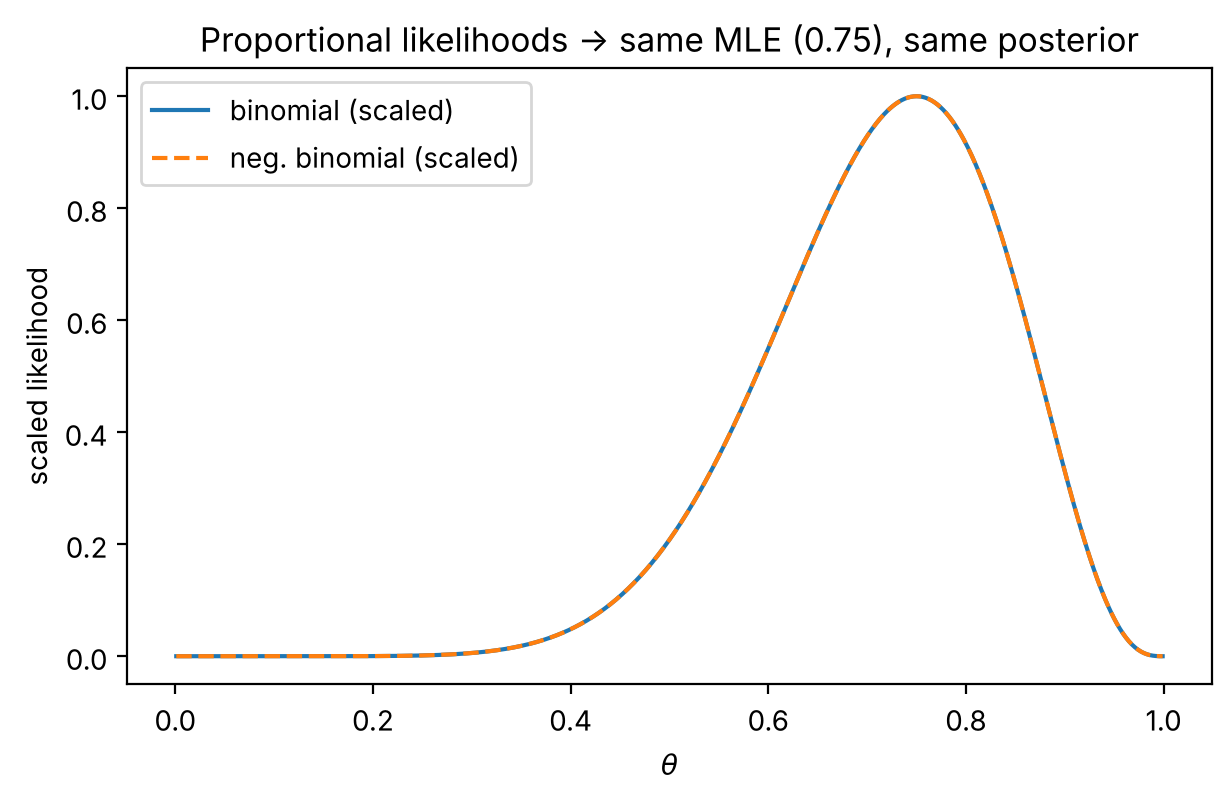

MLE (both): 0.75 0.75


In [5]:
grid = np.linspace(0.001, 0.999, 999)
L1 = stats.binom.pmf(9, 12, grid)
L2 = stats.nbinom.pmf(9, 3, 1 - grid)   # 성공 9번 before 실패 3번 (실패확률 = 1-θ)
plt.plot(grid, L1 / L1.max(), label="binomial (scaled)")
plt.plot(grid, L2 / L2.max(), "--", label="neg. binomial (scaled)")
plt.xlabel(r"$\theta$"); plt.ylabel("scaled likelihood"); plt.legend()
plt.title("Proportional likelihoods -> same MLE (0.75), same posterior")
plt.show()
print("MLE (both):", grid[L1.argmax()].round(3), grid[L2.argmax()].round(3))

## 3. 약한 조건부원리: n=2 또는 n=1000

In [6]:
var_marginal = 0.5 * (1/2) + 0.5 * (1/1000)
print(f"unconditional SE of X̄       : {np.sqrt(var_marginal):.3f}")
print(f"SE given n = 1000 was used  : {np.sqrt(1/1000):.3f}")

unconditional SE of X̄       : 0.500
SE given n = 1000 was used  : 0.032


## 4. 신용구간: 분위수 구간 vs HPD

$X\mid\theta\sim B(10,\theta)$, $\theta\sim Unif(0,1)$, $x=2$ → $\theta\mid x\sim Beta(3,9)$. HPD를 세 가지 방법으로 구해서 비교했다.

In [7]:
post = stats.beta(3, 9)
alpha = 0.05

# (0) 분위수 기반 구간
q_int = post.ppf([alpha/2, 1 - alpha/2])

# (1) 정확한 HPD: 폭이 최소가 되는 하한 분위수 찾기
from scipy.optimize import minimize_scalar
width = lambda p: post.ppf(p + 1 - alpha) - post.ppf(p)
p_opt = minimize_scalar(width, bounds=(0, alpha), method="bounded").x
hpd_exact = post.ppf([p_opt, p_opt + 1 - alpha])

# (2) 그리드 탐색
def hpd_grid(log_unnorm_post, grid, alpha=0.05):
    w = np.exp(log_unnorm_post(grid) - log_unnorm_post(grid).max())
    w = w / w.sum()
    order = np.argsort(w)[::-1]
    M = np.searchsorted(np.cumsum(w[order]), 1 - alpha) + 1
    kept = grid[order[:M]]
    return kept.min(), kept.max()

g = np.linspace(1e-6, 1 - 1e-6, 20_001)
hpd_g = hpd_grid(lambda t: 2*np.log(t) + 8*np.log(1 - t), g)   # θ^2 (1-θ)^8 커널

# (3) 사후표본 기반: 95%를 담는 구간 중 가장 짧은 것
def hpd_sample(samples, alpha=0.05):
    s = np.sort(samples)
    k = int(np.floor((1 - alpha) * len(s)))
    widths = s[k:] - s[:len(s) - k]
    i = widths.argmin()
    return s[i], s[i + k]

hpd_s = hpd_sample(post.rvs(100_000, random_state=rng))

for name, (l, u) in [("quantile", q_int), ("HPD exact", hpd_exact),
                     ("HPD grid", hpd_g), ("HPD sample", hpd_s)]:
    print(f"{name:11s}: ({l:.3f}, {u:.3f})  width = {u - l:.3f}")

quantile   : (0.060, 0.518)  width = 0.458
HPD exact  : (0.041, 0.484)  width = 0.443
HPD grid   : (0.041, 0.484)  width = 0.443
HPD sample : (0.041, 0.486)  width = 0.445


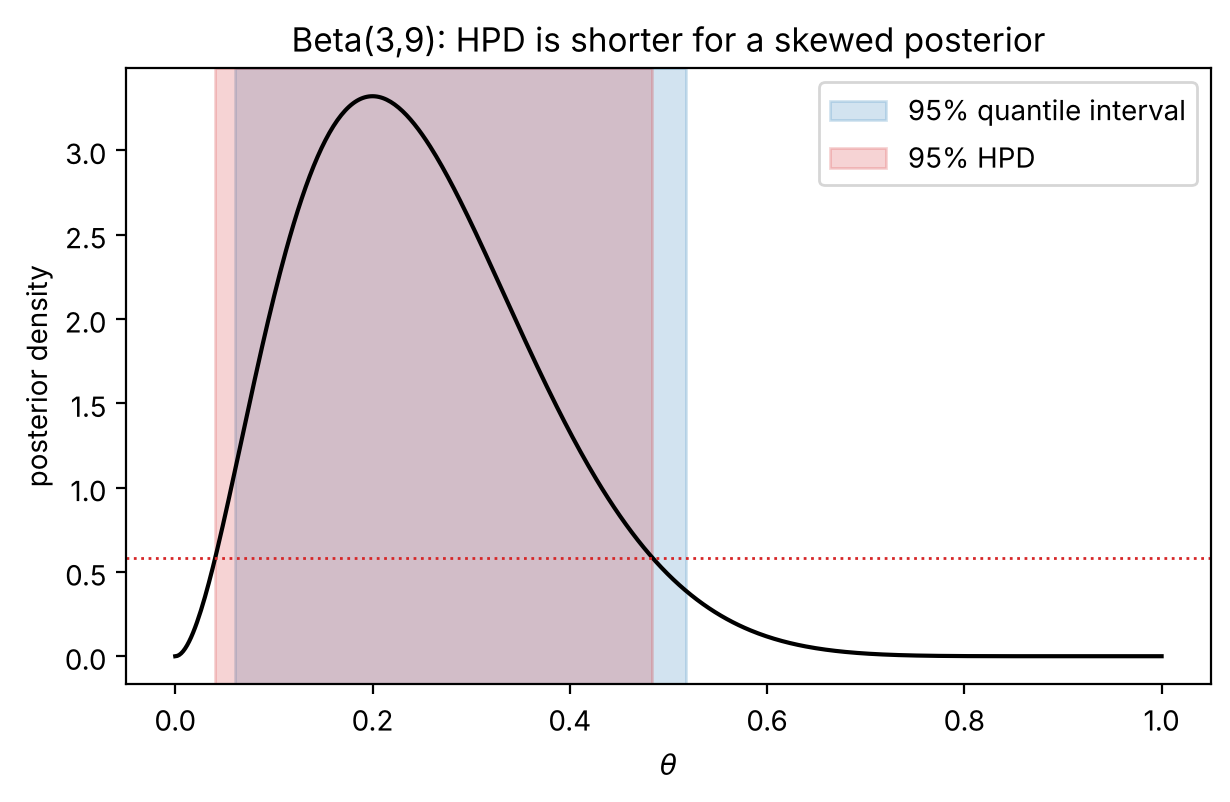

In [8]:
t = np.linspace(0, 1, 500)
plt.plot(t, post.pdf(t), "k")
plt.axvspan(*q_int, alpha=0.2, color="tab:blue", label="95% quantile interval")
plt.axvspan(*hpd_exact, alpha=0.2, color="tab:red", label="95% HPD")
plt.axhline(post.pdf(hpd_exact[0]), ls=":", c="tab:red", lw=1)
plt.xlabel(r"$\theta$"); plt.ylabel("posterior density"); plt.legend()
plt.title("Beta(3,9): HPD is shorter for a skewed posterior")
plt.show()

점선이 HPD를 정하는 수평선 $k$이다. 비대칭 분포라서 분위수 구간은 오른쪽 꼬리를 너무 많이 포함하고, HPD는 밀도가 높은 왼쪽으로 이동한다.

### 다봉 사후분포에서는?

두 정규분포를 섞은 사후분포에서는 HPD 집합이 두 조각으로 끊어진다. 그리드 방법으로 확인.

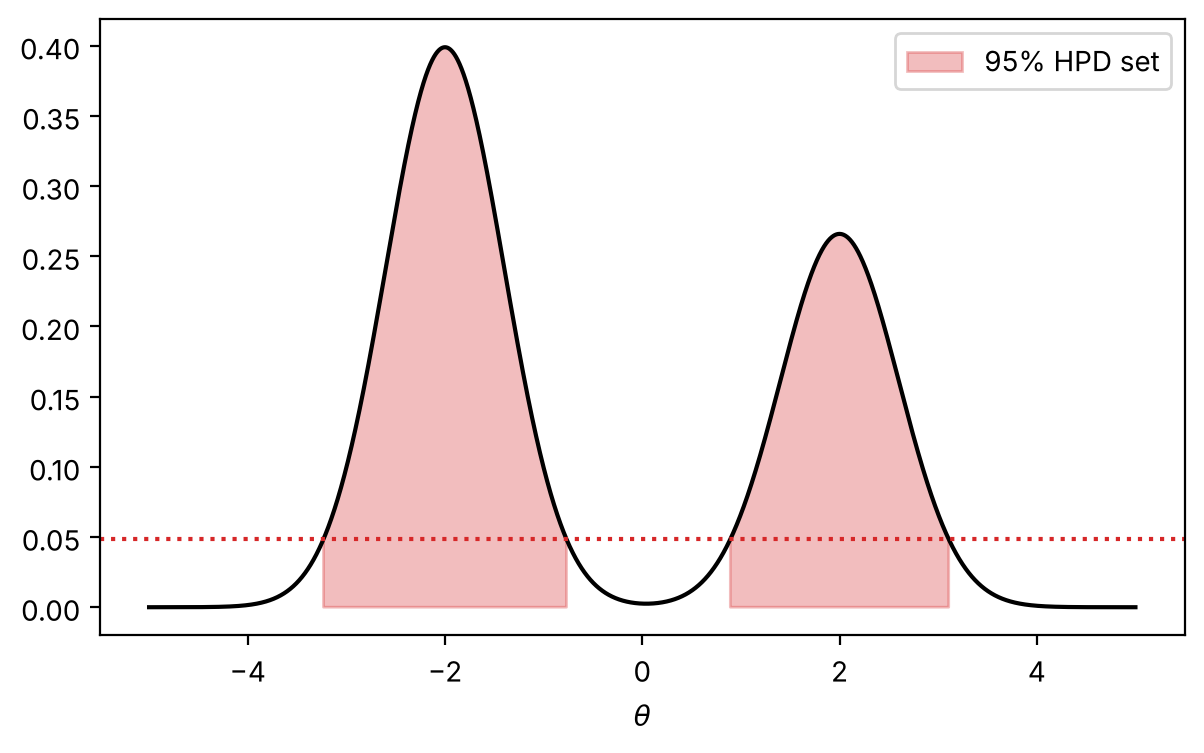

HPD set boundaries: [-3.23 -0.77  0.89  3.11]


In [9]:
mix = lambda t: 0.6 * stats.norm.pdf(t, -2, 0.6) + 0.4 * stats.norm.pdf(t, 2, 0.6)
g = np.linspace(-5, 5, 20_001)
w = mix(g) / mix(g).sum()
order = np.argsort(w)[::-1]
M = np.searchsorted(np.cumsum(w[order]), 0.95) + 1
k = w[order[M - 1]] / (g[1] - g[0])     # 밀도 스케일의 k
inside = mix(g) >= k
plt.plot(g, mix(g), "k")
plt.fill_between(g, 0, mix(g), where=inside, alpha=0.3, color="tab:red", label="95% HPD set")
plt.axhline(k, ls=":", c="tab:red")
plt.legend(); plt.xlabel(r"$\theta$"); plt.show()
edges = g[np.flatnonzero(np.diff(inside.astype(int)) != 0)]
print("HPD set boundaries:", edges.round(2))

## 5. 보충: 가능도 함수는 θ의 pdf가 아니다

$x$를 고정하고 θ로 적분한 값과, θ를 고정하고 $x$로 더한 값을 비교한다.

In [10]:
from scipy import integrate, special

x_obs, n_obs = 9, 12
area_theta, _ = integrate.quad(lambda t: stats.binom.pmf(x_obs, n_obs, t), 0, 1)
sum_x = stats.binom.pmf(np.arange(n_obs + 1), n_obs, 0.3).sum()
print(f"integral of L(theta) over theta : {area_theta:.4f}   (1/(n+1) = {1/(n_obs+1):.4f})")
print(f"sum over x of f(x | theta=0.3)  : {sum_x:.4f}")
# x 가 달라져도 θ 적분값은 항상 1/(n+1) 인지
areas = [integrate.quad(lambda t: stats.binom.pmf(k, n_obs, t), 0, 1)[0] for k in range(n_obs + 1)]
print('min/max over x =', round(min(areas), 4), round(max(areas), 4))

integral of L(theta) over theta : 0.0769   (1/(n+1) = 0.0769)
sum over x of f(x | theta=0.3)  : 1.0000
min/max over x = 0.0769 0.0769


## 6. 보충: 표본평균이 같으면 사후분포도 같다 (충분성)

$N(\theta,1)$ 자료 두 세트를 만들었다. 값은 전혀 다르지만 합(= 표본평균)은 같다. 사전분포는 $N(0,3^2)$.

sums: 4.5 4.5


likelihood ratio  min/max : 16.9455 16.9455  (상수배)
max |posterior_a - posterior_b| = 2.4424906541753444e-15


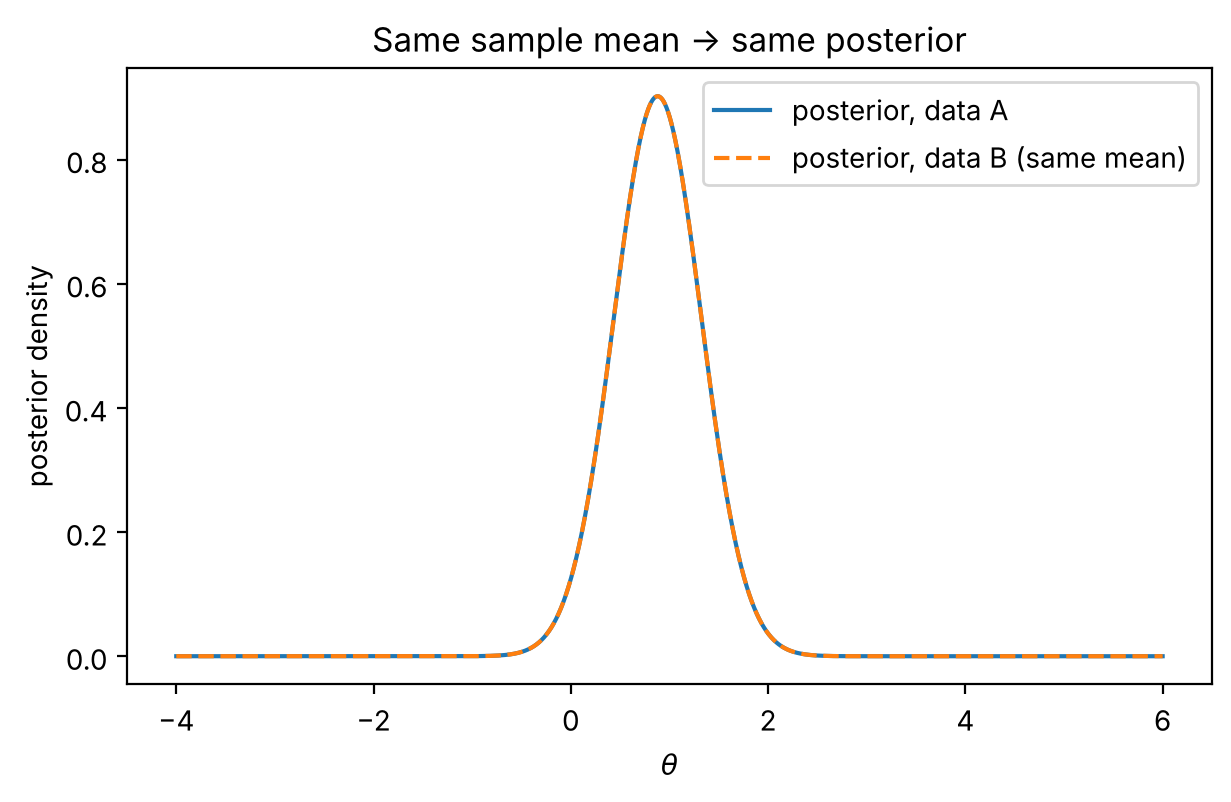

In [11]:
from scipy.integrate import trapezoid

xa = np.array([0.2, 1.5, 2.1, -0.4, 1.1])
xb = np.array([-1.0, 0.0, 0.7, 1.8, 3.0])
print('sums:', xa.sum(), xb.sum())

grid = np.linspace(-4, 6, 4001)
def lik(x):
    return np.exp(stats.norm.logpdf(x[:, None], grid[None, :], 1).sum(axis=0))
def post_grid(x):
    w = lik(x) * stats.norm.pdf(grid, 0, 3)
    return w / trapezoid(w, grid)

pa, pb = post_grid(xa), post_grid(xb)
ratio = lik(xa) / lik(xb)
print('likelihood ratio  min/max :', ratio.min().round(4), ratio.max().round(4), ' (상수배)')
print('max |posterior_a - posterior_b| =', np.abs(pa - pb).max())

plt.plot(grid, pa, label='posterior, data A')
plt.plot(grid, pb, '--', label='posterior, data B (same mean)')
plt.xlabel(r'$\theta$'); plt.ylabel('posterior density'); plt.legend()
plt.title('Same sample mean -> same posterior'); plt.show()

가능도는 θ에 대해 서로 상수배(비는 일정)이고, 정규화하면 사후분포는 완전히 겹친다.

## 7. 보충: 켤레가 아닐 때, $\pi(\theta\mid x)\propto\theta^4e^{-\theta^2}$ ($\theta>0$)

이름이 바로 떠오르지 않는 커널이다. 정규화 상수를 수치적분과 치환($u=\theta^2$)으로 각각 구해 보고, 치환 결과가 맞는지 표본으로 확인한다.

normalizing constant: numeric = 0.664670,  Gamma(5/2)/2 = 0.664670


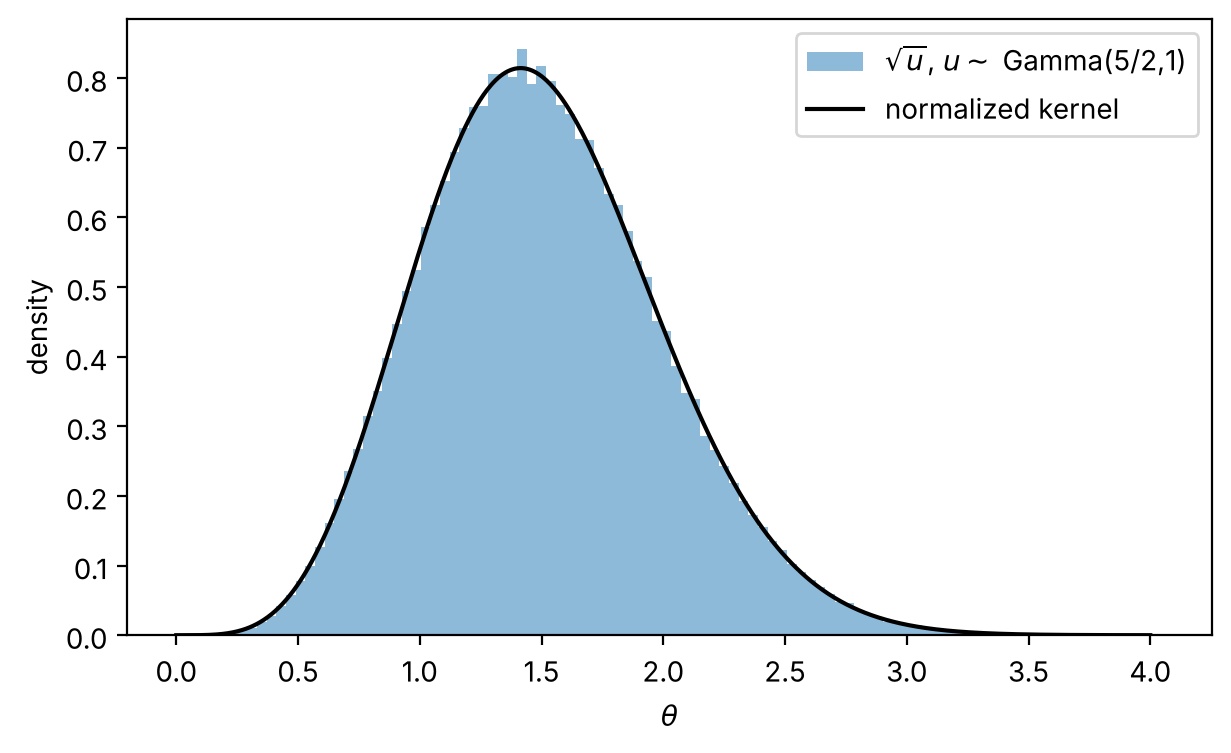

In [12]:
kernel = lambda t: t**4 * np.exp(-t**2)
Z_num, _ = integrate.quad(kernel, 0, np.inf)
Z_exact = special.gamma(2.5) / 2          # u = theta^2 치환 -> Gamma(5/2)/2
print(f"normalizing constant: numeric = {Z_num:.6f},  Gamma(5/2)/2 = {Z_exact:.6f}")

u = stats.gamma(2.5).rvs(200_000, random_state=rng)   # theta^2 ~ Gamma(5/2, 1) 이라면
theta_s = np.sqrt(u)
g = np.linspace(0, 4, 800)
plt.hist(theta_s, bins=100, density=True, alpha=0.5, label=r'$\sqrt{u}$, $u\sim$ Gamma(5/2,1)')
plt.plot(g, kernel(g) / Z_num, 'k', label='normalized kernel')
plt.xlabel(r'$\theta$'); plt.ylabel('density'); plt.legend(); plt.show()

커널을 정규화한 곡선과 치환으로 만든 표본의 히스토그램이 일치한다. 이름 있는 분포로 바로 안 보여도 치환하면 풀리는 경우가 있다는 걸 확인했다.

## 8. 보충: 같은 95%라도 구간마다 폭이 다르다

$\theta\mid x\sim N(0.3,0.5^2)$에서 아래쪽 꼬리 확률 $p$를 바꿔 가며 $(p,\ p+0.95)$ 분위수 구간의 폭을 비교.

quantiles (0.025, 0.975) -> (-0.680, 1.280), width = 1.960
quantiles (0.049, 0.999) -> (-0.527, 1.845), width = 2.372
argmin of width at p = 0.025


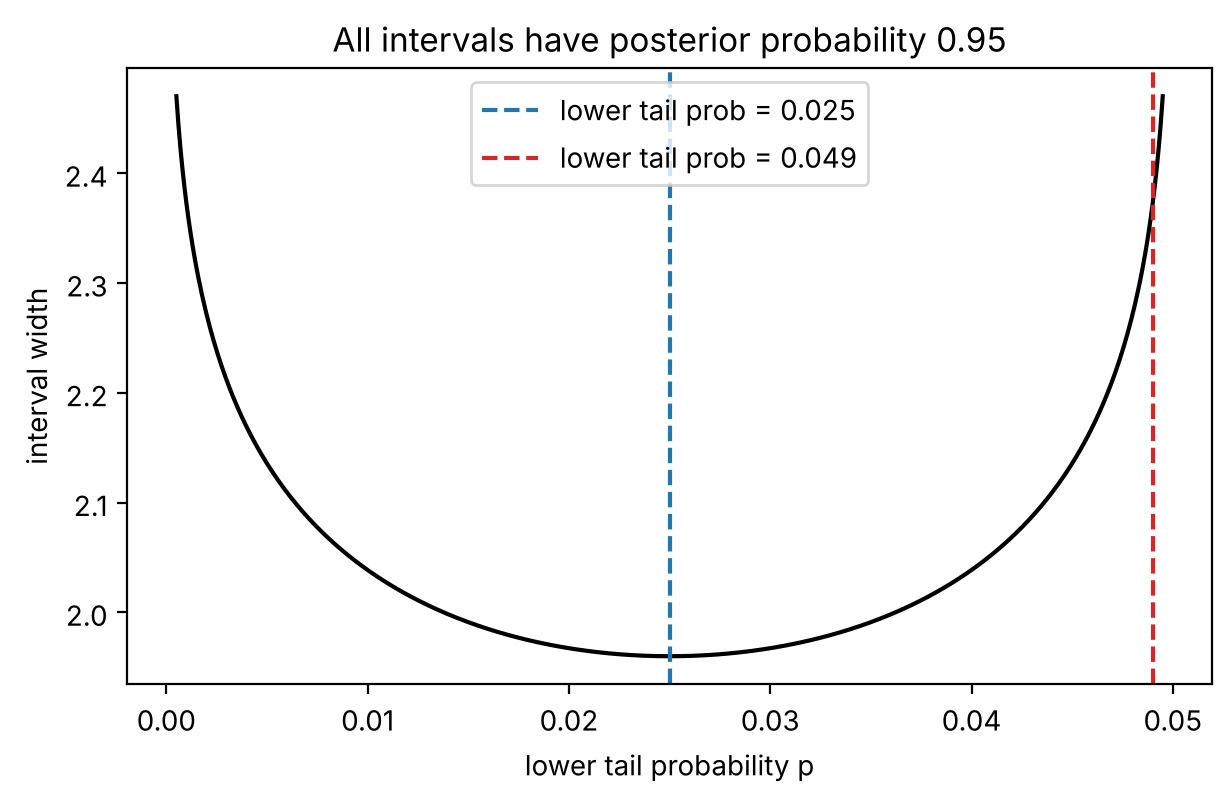

In [13]:
post_n = stats.norm(0.3, 0.5)
for p in (0.025, 0.049):
    lo, hi = post_n.ppf([p, p + 0.95])
    print(f"quantiles ({p}, {p+0.95:.3f}) -> ({lo:.3f}, {hi:.3f}), width = {hi-lo:.3f}")

ps = np.linspace(0.0005, 0.0495, 500)
widths = post_n.ppf(ps + 0.95) - post_n.ppf(ps)
print('argmin of width at p =', ps[widths.argmin()].round(4))
plt.plot(ps, widths, 'k')
for p, c in ((0.025, 'tab:blue'), (0.049, 'tab:red')):
    plt.axvline(p, ls='--', c=c, label=f'lower tail prob = {p}')
plt.xlabel('lower tail probability p'); plt.ylabel('interval width'); plt.legend()
plt.title('All intervals have posterior probability 0.95'); plt.show()

대칭·단봉인 사후분포에서는 양쪽 꼬리를 똑같이(2.5%씩) 자르는 구간이 가장 짧다. 이 경우 분위수 구간이 곧 HPD다.

## 9. 보충: 신뢰구간 vs 신용구간, 반복 실험으로 보면?

$X\mid\theta\sim B(10,\theta)$, 사전분포 $Beta(1,1)$. θ를 하나로 고정하고 데이터를 계속 새로 뽑았을 때 (1) 정확 신뢰구간(Clopper-Pearson)과 (2) 양쪽 꼬리 2.5%씩 자른 신용구간이 θ를 덮는 비율을 정확히 계산한다.

credible : min coverage = 0.000,  average over theta~Unif(0,1) = 0.9507
Clopper-Pearson : min coverage = 0.961,  average = 0.9837
theta=0.05: credible 0.914 | Clopper-Pearson 0.988
theta=0.2: credible 0.967 | Clopper-Pearson 0.994
theta=0.5: credible 0.979 | Clopper-Pearson 0.979


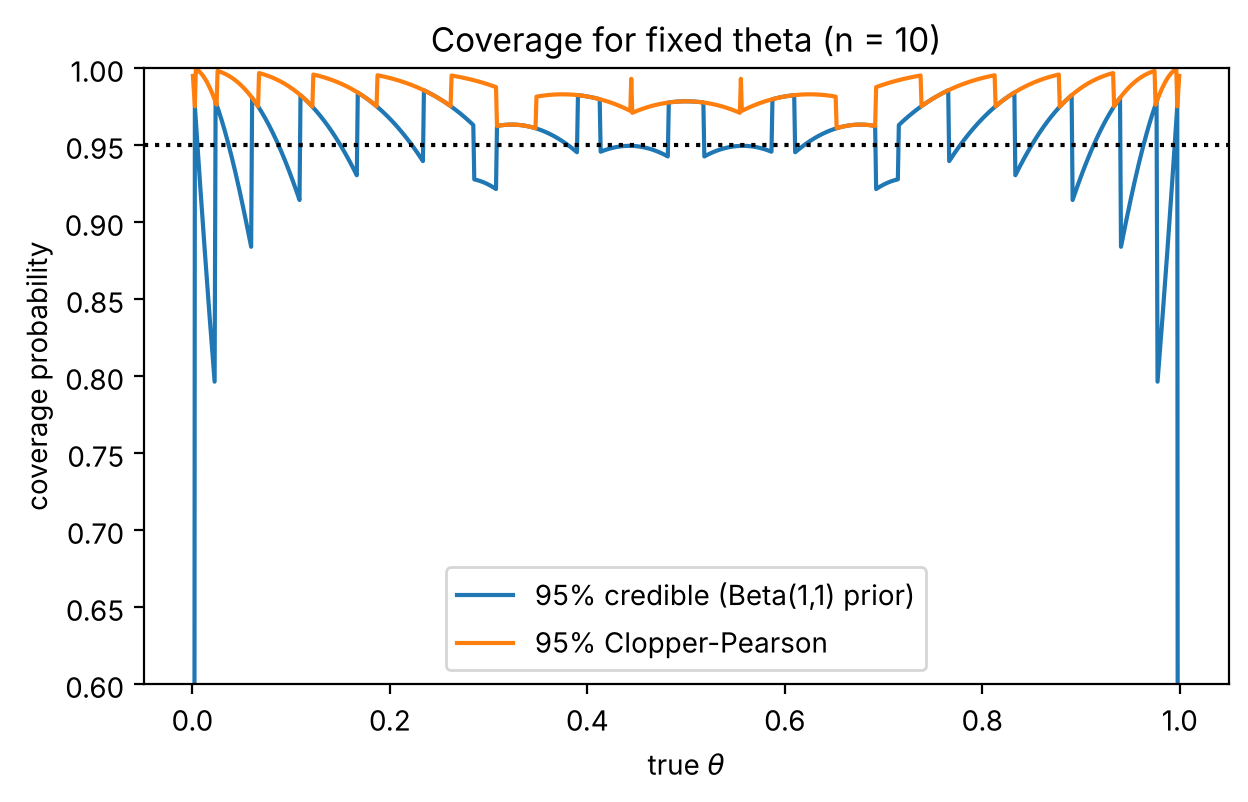

In [14]:
n_c = 10
xs = np.arange(n_c + 1)
cred = np.array([stats.beta.ppf([0.025, 0.975], k + 1, n_c - k + 1) for k in xs])
cp_lo = np.where(xs == 0, 0.0, stats.beta.ppf(0.025, np.maximum(xs, 1), n_c - xs + 1))
cp_hi = np.where(xs == n_c, 1.0, stats.beta.ppf(0.975, xs + 1, np.maximum(n_c - xs, 1)))
cp = np.column_stack([cp_lo, cp_hi])

def coverage(theta, iv):
    inside = (iv[:, 0] <= theta) & (theta <= iv[:, 1])      # x 마다 θ 를 덮는지
    return (stats.binom.pmf(xs, n_c, theta) * inside).sum()

ths = np.linspace(0.0005, 0.9995, 1000)
cov_cred = np.array([coverage(t, cred) for t in ths])
cov_cp = np.array([coverage(t, cp) for t in ths])

print(f"credible : min coverage = {cov_cred.min():.3f},  average over theta~Unif(0,1) = {cov_cred.mean():.4f}")
print(f"Clopper-Pearson : min coverage = {cov_cp.min():.3f},  average = {cov_cp.mean():.4f}")
for t in (0.05, 0.2, 0.5):
    print(f"theta={t}: credible {coverage(t, cred):.3f} | Clopper-Pearson {coverage(t, cp):.3f}")

plt.plot(ths, cov_cred, label='95% credible (Beta(1,1) prior)')
plt.plot(ths, cov_cp, label='95% Clopper-Pearson')
plt.axhline(0.95, c='k', ls=':')
plt.xlabel(r'true $\theta$'); plt.ylabel('coverage probability'); plt.ylim(0.6, 1.0); plt.legend()
plt.title('Coverage for fixed theta (n = 10)'); plt.show()

정리하면:

- Clopper-Pearson은 **어떤 θ에서도** 덮는 비율이 95% 이상이 되도록 만든 구간이라 보수적(대체로 95%보다 큼).
- 신용구간은 θ를 고정하면 95%가 보장되지 않는다. θ=0.05에서는 약 91%, 0.5에서는 약 98%로 출렁이고, θ가 0이나 1에 아주 가까우면 거의 0%까지 떨어진다. 대신 사전분포 $Unif(0,1)$로 θ까지 평균 내면 약 95%가 된다. 신용구간이 약속하는 확률은 "관측 후 θ에 대한 사후확률"이라서 약속의 종류가 다르다.

## 10. 보충: 사전분포 $N(370,21^2)$에서 음수일 확률

In [15]:
from scipy.special import log_ndtr
z = -370 / 21
print(f"z = {z:.3f}")
print(f"P(theta < 0) = {stats.norm.cdf(z):.2e}   (= 10^{log_ndtr(z)/np.log(10):.2f})")
print('0.1**70 =', 0.1**70, '-> P(theta<0) < 0.1**70 ?', stats.norm.cdf(z) < 0.1**70)

z = -17.619
P(theta < 0) = 8.80e-70   (= 10^-69.06)
0.1**70 = 1.0000000000000039e-70 -> P(theta<0) < 0.1**70 ? False
